In [3]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/football.db")

## Przewaga własnego boiska w pięciu ligach

In [4]:
query = """
SELECT
    league,
    COUNT(*) AS matches,
    ROUND(100.0 * SUM(CASE WHEN result = 'H' THEN 1 ELSE 0 END) / COUNT(*), 1) AS home_win_pct,
    ROUND(100.0 * SUM(CASE WHEN result = 'D' THEN 1 ELSE 0 END) / COUNT(*), 1) AS draw_pct,
    ROUND(100.0 * SUM(CASE WHEN result = 'A' THEN 1 ELSE 0 END) / COUNT(*), 1) AS away_win_pct
FROM matches
GROUP BY league
ORDER BY home_win_pct DESC
"""

pd.read_sql_query(query, conn)

,league,matches,home_win_pct,draw_pct,away_win_pct
0,La Liga,4180,45.7,26.0,28.2
1,Premier League,4180,44.3,23.7,32.0
2,Bundesliga,3366,44.2,24.7,31.1
3,Ligue 1,3857,43.8,25.5,30.7
4,Serie A,4180,42.3,25.5,32.2


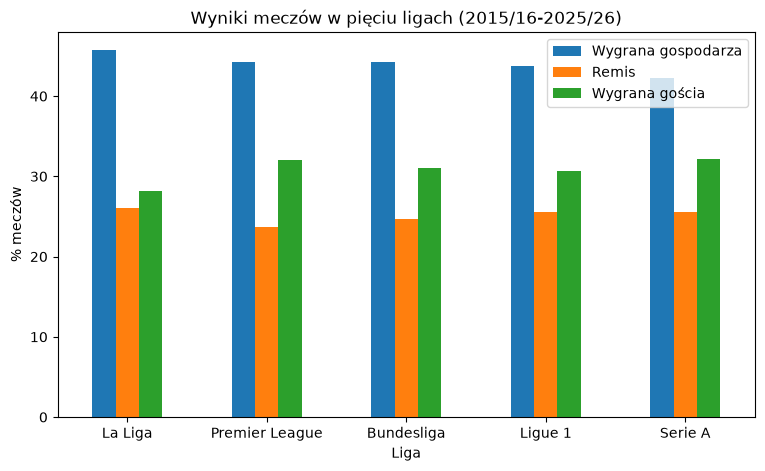

In [5]:
import matplotlib.pyplot as plt

results = pd.read_sql_query(query, conn)
chart_data = results.set_index("league")[["home_win_pct", "draw_pct", "away_win_pct"]]

chart_data.plot(kind="bar", figsize=(9, 5))
plt.title("Wyniki meczów w pięciu ligach (2015/16-2025/26)")
plt.xlabel("Liga")
plt.ylabel("% meczów")
plt.xticks(rotation=0)
plt.legend(["Wygrana gospodarza", "Remis", "Wygrana gościa"])
plt.show()

Przewaga własnego boiska w pięciu ligach

W latach 2015/16-2025/26 gospodarze wygrywali od 42,3% (Serie A) do 45,7% (La Liga) meczów, a goście od 28,2% do 32,2%. We wszystkich ligach gospodarz wygrywał wyraźnie częściej niż gość. Premier League, Bundesliga i Ligue 1 wypadają niemal tak samo (około 44%). La Liga ma największą przewagę gospodarzy, a Serie A najmniejszą.

____________________________

___________

## Czy przewaga własnego boiska jest stała?

In [6]:
query_seasons = """
SELECT
    league,
    season,
    ROUND(100.0 * SUM(CASE WHEN result = 'H' THEN 1 ELSE 0 END) / COUNT(*), 1) AS home_win_pct
FROM matches
GROUP BY league, season
ORDER BY league, season
"""

by_season = pd.read_sql_query(query_seasons, conn)
by_season.head(12)

,league,season,home_win_pct
0,Bundesliga,2015/16,44.1
1,Bundesliga,2016/17,49.0
2,Bundesliga,2017/18,45.4
3,Bundesliga,2018/19,45.1
4,Bundesliga,2019/20,40.2
5,Bundesliga,2020/21,42.2
6,Bundesliga,2021/22,46.7
7,Bundesliga,2022/23,47.4
8,Bundesliga,2023/24,43.8
9,Bundesliga,2024/25,38.6


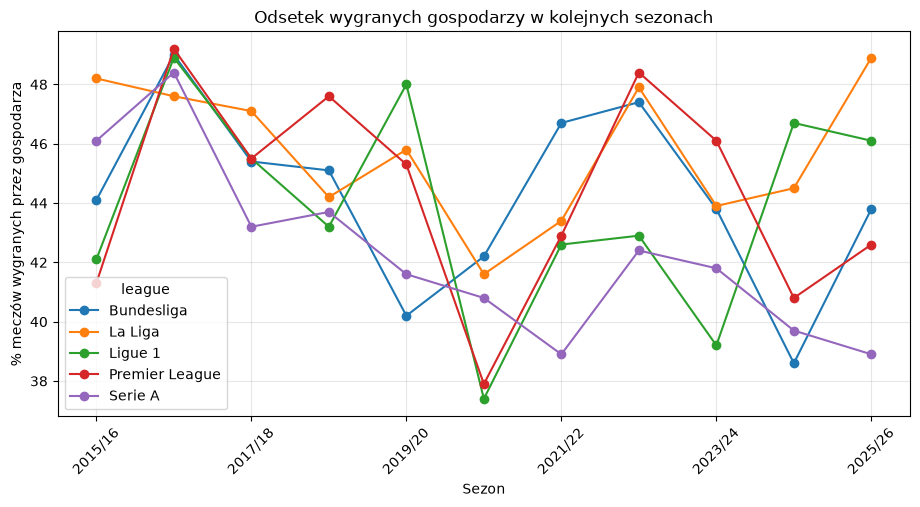

In [7]:
pivot = by_season.pivot(index="season", columns="league", values="home_win_pct")

pivot.plot(figsize=(11, 5), marker="o")
plt.title("Odsetek wygranych gospodarzy w kolejnych sezonach")
plt.xlabel("Sezon")
plt.ylabel("% meczów wygranych przez gospodarza")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

In [8]:
comparison = pd.DataFrame({
    "średnia pozostałych sezonów": pivot.drop("2020/21").mean().round(1),
    "sezon 2020/21": pivot.loc["2020/21"],
})
comparison["różnica"] = comparison["sezon 2020/21"] - comparison["średnia pozostałych sezonów"]
comparison["różnica"] = comparison["różnica"].round(1)
comparison

,średnia pozostałych sezonów,sezon 2020/21,różnica
league,,,
Bundesliga,44.4,42.2,-2.2
La Liga,46.1,41.6,-4.5
Ligue 1,44.5,37.4,-7.1
Premier League,45.0,37.9,-7.1
Serie A,42.5,40.8,-1.7


Czy przewaga własnego boiska jest stała?

Odsetek wygranych gospodarzy zmienia się z sezonu na sezon o kilka punktów procentowych we wszystkich pięciu ligach. W sezonie 2020/21, granym w dużej części bez kibiców, spadł w każdej lidze poniżej swojej średniej z pozostałych sezonów, najmocniej w Premier League i Ligue 1 (o 7,1 pkt proc. w obu), mniej w La Lidze (o 4,5 pkt proc.), a najmniej w Bundeslidze (o 2,2 pkt proc.) i Serie A (o 1,7 pkt proc.).  Wynik sugeruje, że obecność publiczności zwiększa przewagę gospodarza, ale sam wykres nie dowodzi związku przyczynowego.


_____________________________________________________________________________

___________

## Która liga jest najbardziej bramkowa?

In [9]:
query_goals = """
SELECT
    league,
    ROUND(AVG(home_goals + away_goals), 2) AS goals_per_match,
    ROUND(AVG(home_goals), 2) AS home_goals_avg,
    ROUND(AVG(away_goals), 2) AS away_goals_avg
FROM matches
GROUP BY league
ORDER BY goals_per_match DESC
"""

pd.read_sql_query(query_goals, conn)

,league,goals_per_match,home_goals_avg,away_goals_avg
0,Bundesliga,3.07,1.71,1.36
1,Premier League,2.82,1.55,1.27
2,Serie A,2.73,1.48,1.25
3,Ligue 1,2.71,1.51,1.20
4,La Liga,2.63,1.50,1.13


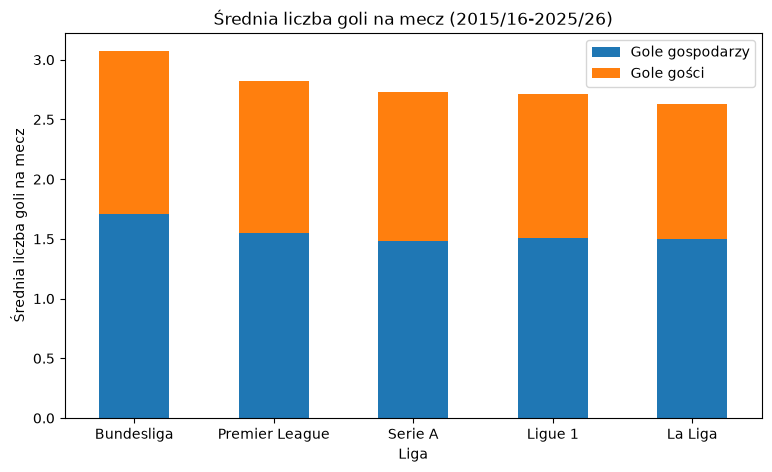

In [10]:
goals = pd.read_sql_query(query_goals, conn)
goals_chart = goals.set_index("league")[["home_goals_avg", "away_goals_avg"]]

goals_chart.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Średnia liczba goli na mecz (2015/16-2025/26)")
plt.xlabel("Liga")
plt.ylabel("Średnia liczba goli na mecz")
plt.xticks(rotation=0)
plt.legend(["Gole gospodarzy", "Gole gości"])
plt.show()

Która liga jest najbardziej bramkowa?

Najwięcej goli pada w Bundeslidze (średnio 3,07 na mecz), a najmniej w La Lidze (2,63). Premier League (2,82), Serie A (2,73) i Ligue 1 (2,71) są blisko siebie. We wszystkich ligach gospodarze strzelają więcej goli niż goście, a różnica jest największa w La Lidze (0,37 gola na mecz) i najmniejsza w Serie A (0,23). Pasuje to do wyników z pierwszego pytania, gdzie La Liga miała największy odsetek wygranych gospodarzy, a Serie A najmniejszy.

In [11]:
query_goals_season = """
SELECT
    league,
    season,
    ROUND(AVG(home_goals + away_goals), 2) AS goals_per_match
FROM matches
GROUP BY league, season
ORDER BY league, season
"""

goals_by_season = pd.read_sql_query(query_goals_season, conn)
goals_pivot = goals_by_season.pivot(index="season", columns="league", values="goals_per_match")
goals_pivot

league,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
season,,,,,
2015/16,2.83,2.74,2.53,2.70,2.58
2016/17,2.87,2.94,2.62,2.80,2.96
2017/18,2.79,2.69,2.72,2.68,2.68
2018/19,3.18,2.59,2.56,2.82,2.68
2019/20,3.21,2.48,2.52,2.72,3.04
2020/21,3.03,2.51,2.76,2.69,3.05
2021/22,3.12,2.50,2.81,2.82,2.87
2022/23,3.17,2.51,2.81,2.85,2.56
2023/24,3.22,2.64,2.70,3.28,2.61


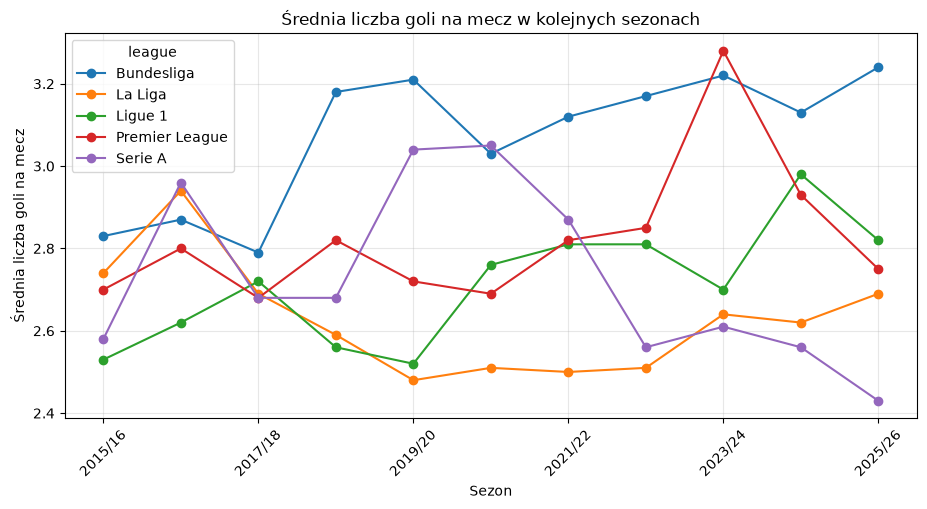

In [12]:
goals_pivot.plot(figsize=(11, 5), marker="o")
plt.title("Średnia liczba goli na mecz w kolejnych sezonach")
plt.xlabel("Sezon")
plt.ylabel("Średnia liczba goli na mecz")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()



Bundesliga miała najwyższą średnią liczbę goli na mecz w 8 z 11 sezonów. Wyjątki to 2016/17 (Serie A 2,96 i La Liga 2,94 wobec 2,87 w Bundeslidze), 2020/21 (Serie A 3,05 wobec 3,03) i 2023/24 (Premier League 3,28 wobec 3,22). Bundesliga zwiększyła średnią z około 2,8 w pierwszych trzech sezonach do ponad 3,0 od sezonu 2018/19. La Liga miała najmniej goli w sezonach 2019/20-2022/23 (około 2,5 na mecz), a Serie A spadła z 3,05 w 2020/21 do 2,43 w 2025/26. W przeciwieństwie do odsetka wygranych gospodarzy, sezon 2020/21 nie wyróżnia się pod względem liczby goli: w dwóch ligach średnia spadła, a w trzech wzrosła.

____________________

______________


## Która liga ma najwięcej fauli i kartek?

In [13]:
query_aggression = """
SELECT
    league,
    ROUND(AVG(home_fouls + away_fouls), 1) AS fouls_per_match,
    ROUND(AVG(home_yellow + away_yellow), 2) AS yellow_per_match,
    ROUND(AVG(home_red + away_red), 3) AS red_per_match
FROM matches
GROUP BY league
ORDER BY yellow_per_match DESC
"""

pd.read_sql_query(query_aggression, conn)

,league,fouls_per_match,yellow_per_match,red_per_match
0,La Liga,26.5,4.90,0.239
1,Serie A,26.4,4.41,0.224
2,Bundesliga,24.3,3.77,0.148
3,Ligue 1,25.2,3.72,0.256
4,Premier League,21.5,3.47,0.119


In [14]:
query_strictness = """
SELECT
    league,
    ROUND(100.0 * SUM(home_yellow + away_yellow) / SUM(home_fouls + away_fouls), 1) AS yellow_per_100_fouls
FROM matches
GROUP BY league
ORDER BY yellow_per_100_fouls DESC
"""

pd.read_sql_query(query_strictness, conn)

,league,yellow_per_100_fouls
0,La Liga,18.5
1,Serie A,16.7
2,Premier League,16.2
3,Bundesliga,15.5
4,Ligue 1,14.7


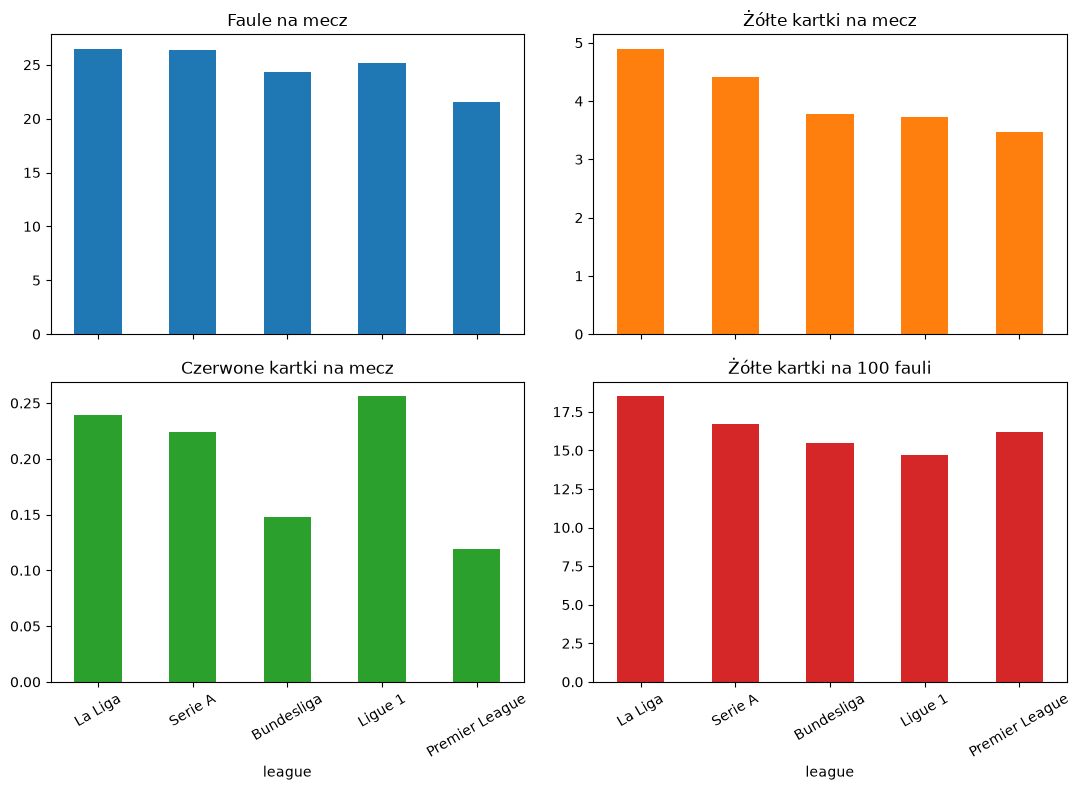

In [15]:
aggr = pd.read_sql_query(query_aggression, conn)
strict = pd.read_sql_query(query_strictness, conn)

agg_all = aggr.merge(strict, on="league").set_index("league")
agg_all.columns = [
    "Faule na mecz",
    "Żółte kartki na mecz",
    "Czerwone kartki na mecz",
    "Żółte kartki na 100 fauli",
]

agg_all.plot(
    kind="bar",
    subplots=True,
    layout=(2, 2),
    figsize=(11, 8),
    legend=False,
    rot=30,
    title=list(agg_all.columns),
)
plt.tight_layout()
plt.show()

Która liga ma najwięcej fauli i kartek?

Najwięcej fauli i żółtych kartek notuje La Liga (26,5 faula i 4,90 żółtej kartki na mecz), a najmniej Premier League (21,5 i 3,47). La Liga ma też najsurowszych sędziów względem liczby fauli: 18,5 żółtej kartki na 100 fauli, czyli jedną żółtą kartkę mniej więcej co 5,4 faula. W Ligue 1 jest to 14,7 (co 6,8 faula), a jednocześnie liga ta ma najwięcej czerwonych kartek na mecz (0,256), choć różnica względem La Ligi i Serie A jest niewielka. Mała liczba kartek w Premier League wynika głównie z małej liczby fauli, bo pod względem żółtych kartek na 100 fauli liga ta jest w środku stawki (16,2). Dane nie pozwalają odróżnić stylu gry zawodników od podejścia sędziów i przepisów obowiązujących w danej lidze.